In [2]:
import pandas as pd, io

with open("marketing_campaign.csv", encoding="utf-8-sig") as f:
    lines = [l.strip().strip('"') for l in f.read().splitlines()]

raw = pd.read_csv(io.StringIO("\n".join(lines)), sep="\t")
print(raw.shape)                      # (2240, 29)
raw.isna().sum()[lambda s: s > 0]     # only Income has missing values (24)

(2240, 29)


Income    24
dtype: int64

In [3]:
df = raw.copy()

# Dates are day-month-year
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")

# Remove rows with missing income (24 rows)
df = df.dropna(subset=["Income"])

# Remove impossible birth years (1893, 1899, 1900: 3 rows)
df = df[df["Year_Birth"] >= 1940]

# Rename columns to match your sheet
df = df.rename(columns={"MntWines": "MntDrinks",
                        "NumCatalogPurchases": "NumAppPurchases"})

In [4]:
spend_cols = ["MntDrinks", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts"]
df["Total_spend"]    = df[spend_cols].sum(axis=1)
df["Total_children"] = df["Kidhome"] + df["Teenhome"]
df["Age"]            = 2025 - df["Year_Birth"]
df["Total Tenure"]   = (pd.Timestamp("2025-12-08") - df["Dt_Customer"]).dt.days

df["Total Purchase"] = df[["MntMeatProducts", "MntFishProducts", "MntSweetProducts",
                           "NumDealsPurchases", "NumWebPurchases",
                           "NumAppPurchases", "NumStorePurchases"]].sum(axis=1)

In [5]:
keep = ["ID","Year_Birth","Education","Marital_Status","Income","Kidhome","Teenhome",
        "Dt_Customer","Recency","MntDrinks","MntFruits","MntMeatProducts","MntFishProducts",
        "MntSweetProducts","NumDealsPurchases","NumWebPurchases","NumAppPurchases",
        "NumStorePurchases","NumWebVisitsMonth","Total_spend","Total_children",
        "Total Purchase","Age","Total Tenure"]
df = df[keep].reset_index(drop=True)
df.to_csv("cleaned_data.csv", index=False) 

In [6]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

num = df.drop(columns=["ID"]).select_dtypes("number")
desc = num.describe().T
desc["skew"] = num.skew()
desc["kurtosis"] = num.kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Year_Birth,2213.0,1968.92,11.70,1940.0,1959.0,1970.0,1977.0,1996.0,-0.09,-0.80
Income,2213.0,52236.58,25178.60,1730.0,35246.0,51373.0,68487.0,666666.0,6.77,159.73
Kidhome,2213.0,0.44,0.54,0.0,0.0,0.0,1.0,2.0,0.64,-0.79
Teenhome,2213.0,0.51,0.54,0.0,0.0,0.0,1.0,2.0,0.41,-0.99
Recency,2213.0,49.01,28.94,0.0,24.0,49.0,74.0,99.0,0.00,-1.20
MntDrinks,2213.0,305.15,337.31,0.0,24.0,175.0,505.0,1493.0,1.17,0.59
MntFruits,2213.0,26.32,39.74,0.0,2.0,8.0,33.0,199.0,2.10,4.08
MntMeatProducts,2213.0,166.96,224.23,0.0,16.0,68.0,232.0,1725.0,2.03,5.07
MntFishProducts,2213.0,37.64,54.76,0.0,3.0,12.0,50.0,259.0,1.92,3.08
MntSweetProducts,2213.0,27.03,41.09,0.0,1.0,8.0,33.0,262.0,2.10,4.10


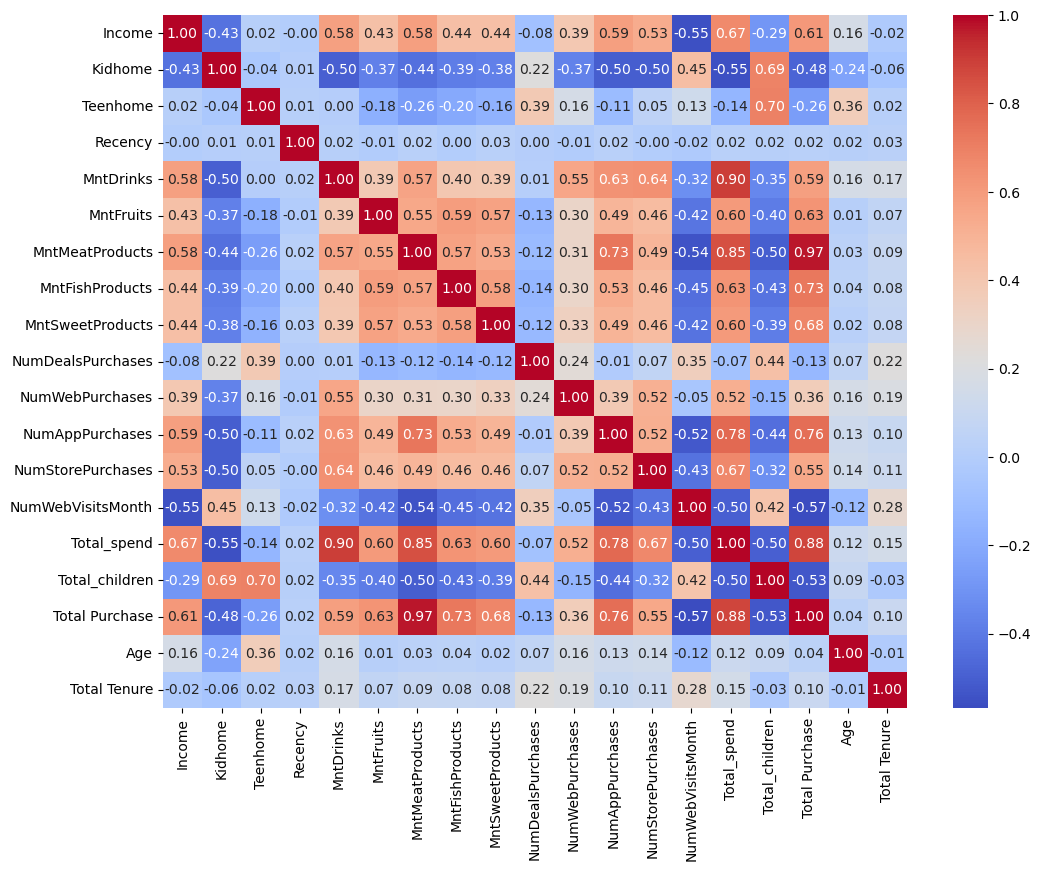

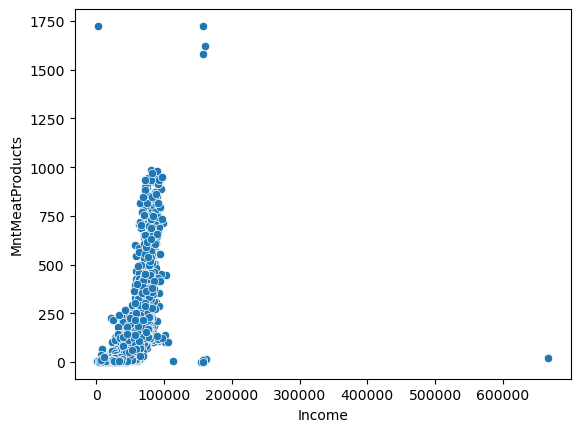

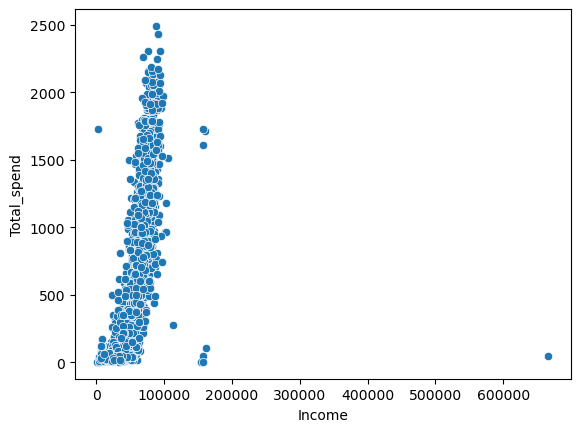

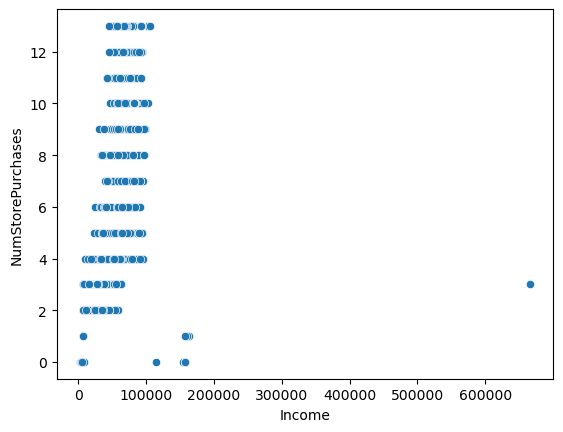

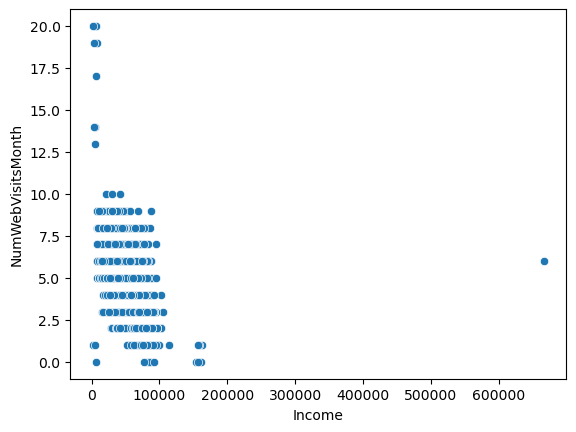

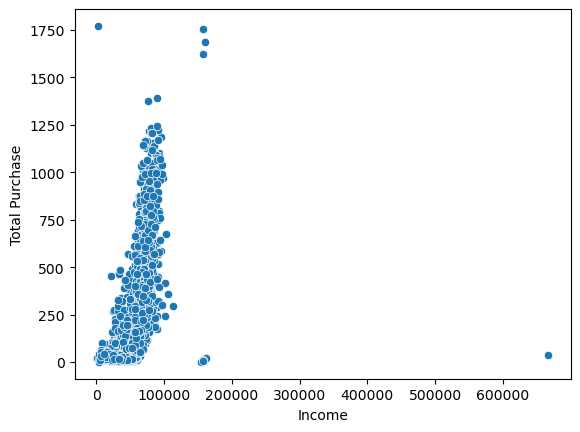

In [7]:
plt.figure(figsize=(12, 9))
sns.heatmap(num.drop(columns="Year_Birth").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

for y in ["MntMeatProducts", "Total_spend", "NumStorePurchases", "NumWebVisitsMonth", "Total Purchase"]:
    sns.scatterplot(data=df, x="Income", y=y)
    plt.show()

In [8]:
# a) Paired t-test: web vs store purchases
t, p = stats.ttest_rel(df["NumWebPurchases"], df["NumStorePurchases"])
print(f"t = {t:.3f}, p = {p:.3g}")

# b) One-way ANOVA: Total_spend across Education levels
groups = [g["Total_spend"] for _, g in df.groupby("Education")]
F, p = stats.f_oneway(*groups)
print(f"F = {F:.3f}, p = {p:.3g}")

# c) Chi-square: Education vs spend category
df["Spend_Category"] = pd.qcut(df["Total_spend"], 3, labels=["Low", "Medium", "High"])
obs = pd.crosstab(df["Education"], df["Spend_Category"])
chi2, p, dof, exp = stats.chi2_contingency(obs)
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p:.3g}")

t = -27.099, p = 6.77e-140
F = 14.822, p = 5.9e-12
chi2 = 112.56, df = 8, p = 1.14e-20


In [9]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print(pairwise_tukeyhsd(df["Total_spend"], df["Education"]))

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1     group2    meandiff p-adj    lower     upper   reject
-----------------------------------------------------------------
  2n Cycle      Basic -393.3098 0.0001 -632.1369 -154.4826   True
  2n Cycle Graduation    118.73  0.054   -1.2326  238.6926  False
  2n Cycle     Master  117.3054  0.135  -20.0002  254.6109  False
  2n Cycle        PhD  190.0064 0.0008   58.6128  321.4001   True
     Basic Graduation  512.0397    0.0  295.2809  728.7986   True
     Basic     Master  510.6151    0.0  283.7976  737.4326   True
     Basic        PhD  583.3162    0.0  360.0279  806.6045   True
Graduation     Master   -1.4246    1.0  -95.2266   92.3773  False
Graduation        PhD   71.2765 0.1479   -13.637  156.1899  False
    Master        PhD   72.7011 0.3524  -35.3363  180.7385  False
-----------------------------------------------------------------


In [10]:
X = sm.add_constant(df[["Total_children", "Recency", "NumDealsPurchases", "NumWebPurchases"]])
model = sm.OLS(df["Total_spend"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Total_spend   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     449.2
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          1.60e-283
Time:                        15:02:50   Log-Likelihood:                -16550.
No. Observations:                2213   AIC:                         3.311e+04
Df Residuals:                    2208   BIC:                         3.314e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               458.6843     26.29

            Variable       VIF
0     Total_children  1.349291
1            Recency  1.000365
2  NumDealsPurchases  1.400323
3    NumWebPurchases  1.159791


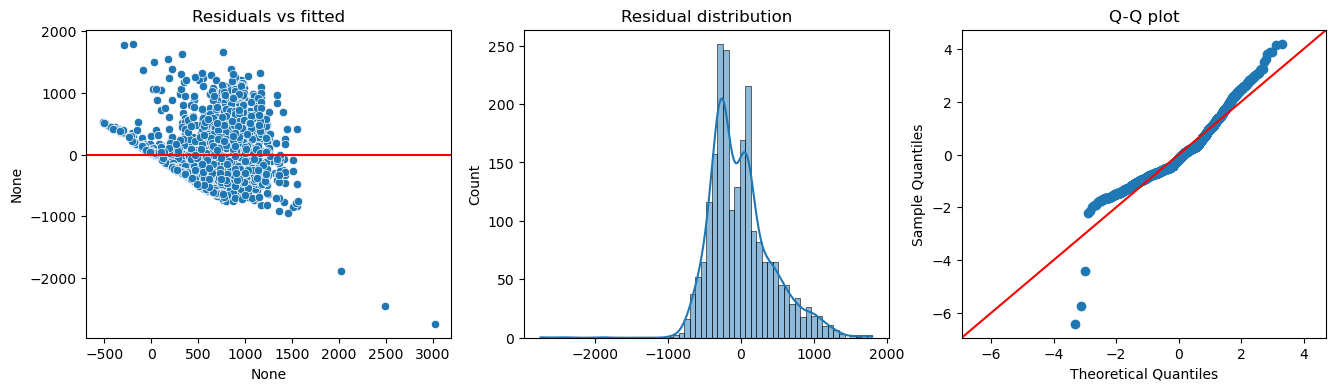

Breusch-Pagan p = 1.106887837122547e-37
Durbin-Watson   = 1.9889582901039642


In [11]:
# Multicollinearity (VIF)
vif = pd.DataFrame({"Variable": X.columns[1:],
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]})
print(vif)   # values under 5 (or 10) are fine

# Residual plots
resid, fitted = model.resid, model.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(x=fitted, y=resid, ax=ax[0]); ax[0].axhline(0, color="red"); ax[0].set_title("Residuals vs fitted")
sns.histplot(resid, kde=True, ax=ax[1]); ax[1].set_title("Residual distribution")
sm.qqplot(resid, line="45", fit=True, ax=ax[2]); ax[2].set_title("Q-Q plot")
plt.show()

# Heteroscedasticity and autocorrelation
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
print("Breusch-Pagan p =", het_breuschpagan(resid, X)[1])
print("Durbin-Watson   =", durbin_watson(resid))

In [12]:
robust = sm.OLS(df["Total_spend"], X).fit(cov_type="HC3")
print(robust.summary())

                            OLS Regression Results                            
Dep. Variable:            Total_spend   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     300.0
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          3.23e-206
Time:                        15:03:11   Log-Likelihood:                -16550.
No. Observations:                2213   AIC:                         3.311e+04
Df Residuals:                    2208   BIC:                         3.314e+04
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               458.6843     34.84